# 03 — Development-Only Exploratory Data Analysis (EDA)

## Purpose & Scope
This notebook performs comprehensive Exploratory Data Analysis (EDA) on the **development partition (80,000 records)** of the Employee Resignation dataset, strictly excluding the **formal holdout partition (20,000 records)** to prevent data leakage and benchmark contamination.

### Objectives
1. **Target Distribution & Class Imbalance Analysis**: Quantify the baseline prevalence of `Resigned` employees and establish strategies for handling class imbalance.
2. **Categorical Features & Resignation Rates**: Explore distribution patterns and conditional resignation rates across categorical predictors (`Department`, `Gender`, `Job_Title`, `Education_Level`).
3. **Numerical & Ordinal Features**: Analyze summary statistics, central tendencies, spreads, and distributions across numerical features for stayed vs. resigned employees.
4. **Feature Correlation & Redundancy**: Evaluate inter-feature relationships and potential multicollinearity using correlation matrices.
5. **Construction & Structural Patterns**: Audit domain-specific relationships (e.g., `Monthly_Salary` vs. `Job_Title` & `Performance_Score`, `Hire_Date` vs. `Years_At_Company`).
6. **Sensitive Attribute Demographics**: Examine sensitive group distributions (`Gender` and `Age` sub-groups) and analyze sub-group target rates under an association-only framing.

---

### Strict Leakage Governance Rules
- **Development Partition Only**: All visualizations, summary statistics, and conclusions are derived exclusively from the 80,000 development records identified in `data/processed/split_registry.csv`.
- **Formal Holdout Exclusion**: The 20,000 formal holdout records are never inspected or included in calculations.
- **Predictor Set Integrity**: All 17 primary predictors defined in `configs/feature_contract.yaml` are evaluated. `Employee_ID` and raw `Hire_Date` are excluded from predictive modeling.

## 1. Environment Setup & Data Loading

We begin by setting up the Python environment, configuring pandas display options, defining directory paths using `pathlib.Path`, and merging the raw dataset with the split registry to isolate the development partition.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure pandas display options per project standards
pd.set_option("display.max_columns", None)

# Configure plot aesthetic defaults
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

# Resolve project root relative to notebook directory
project_root = Path("..").resolve()
raw_data_path = project_root / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
registry_path = project_root / "data" / "processed" / "split_registry.csv"
results_eda_dir = project_root / "results" / "eda"

# Ensure output directory exists
results_eda_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Raw dataset path:", raw_data_path)
print("Split registry path:", registry_path)
print("EDA results directory:", results_eda_dir)

Project root: D:\Desktop\Employee_Resignation_Prediction
Raw dataset path: D:\Desktop\Employee_Resignation_Prediction\data\raw\Extended_Employee_Performance_and_Productivity_Data.csv
Split registry path: D:\Desktop\Employee_Resignation_Prediction\data\processed\split_registry.csv
EDA results directory: D:\Desktop\Employee_Resignation_Prediction\results\eda


In [4]:
# Load raw dataset and split registry
df_raw = pd.read_csv(raw_data_path)
df_registry = pd.read_csv(registry_path)

print(f"Raw dataset shape before merge: {df_raw.shape}")
print(f"Split registry shape before merge: {df_registry.shape}")

# Merge raw data with registry on Employee_ID
df_merged = df_raw.merge(df_registry, on="Employee_ID", how="inner")
print(f"Merged dataset shape: {df_merged.shape}")

# Filter strictly for development partition
df_dev = df_merged[df_merged["partition"] == "development"].copy()

# Log shapes before and after filtering
print(f"Shape after filtering for development partition: {df_dev.shape}")
print(f"Excluded formal holdout shape: {df_merged[df_merged['partition'] == 'holdout'].shape}")

# Validate expected row count
assert len(df_dev) == 80000, f"Expected 80,000 development rows, got {len(df_dev)}"
print("✅ Development dataset successfully isolated (80,000 rows).")

Raw dataset shape before merge: (100000, 20)
Split registry shape before merge: (100000, 3)
Merged dataset shape: (100000, 22)
Shape after filtering for development partition: (80000, 22)
Excluded formal holdout shape: (20000, 22)
✅ Development dataset successfully isolated (80,000 rows).


## 2. Target Variable Distribution & Class Imbalance

We inspect the distribution of the target variable `Resigned` (Boolean) to quantify class imbalance in the development set and guide evaluation metric selection and modeling strategies.

In [5]:
# Target variable frequency and percentage
target_counts = df_dev["Resigned"].value_counts()
target_percentages = df_dev["Resigned"].value_counts(normalize=True) * 100

target_df = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})
target_df.index.name = "Resigned"

print("--- Target Distribution in Development Partition ---")
print(target_df)

imbalance_ratio = target_counts[False] / target_counts[True]
print(f"\nClass Imbalance Ratio (Non-Resigned : Resigned): {imbalance_ratio:.2f} : 1")
print(f"Resignation Prevalence: {target_percentages[True]:.2f}%")

--- Target Distribution in Development Partition ---
          Count  Percentage (%)
Resigned                       
False     71992           89.99
True       8008           10.01

Class Imbalance Ratio (Non-Resigned : Resigned): 8.99 : 1
Resignation Prevalence: 10.01%


Saved development dataset summary to results/eda/development_dataset_summary.csv


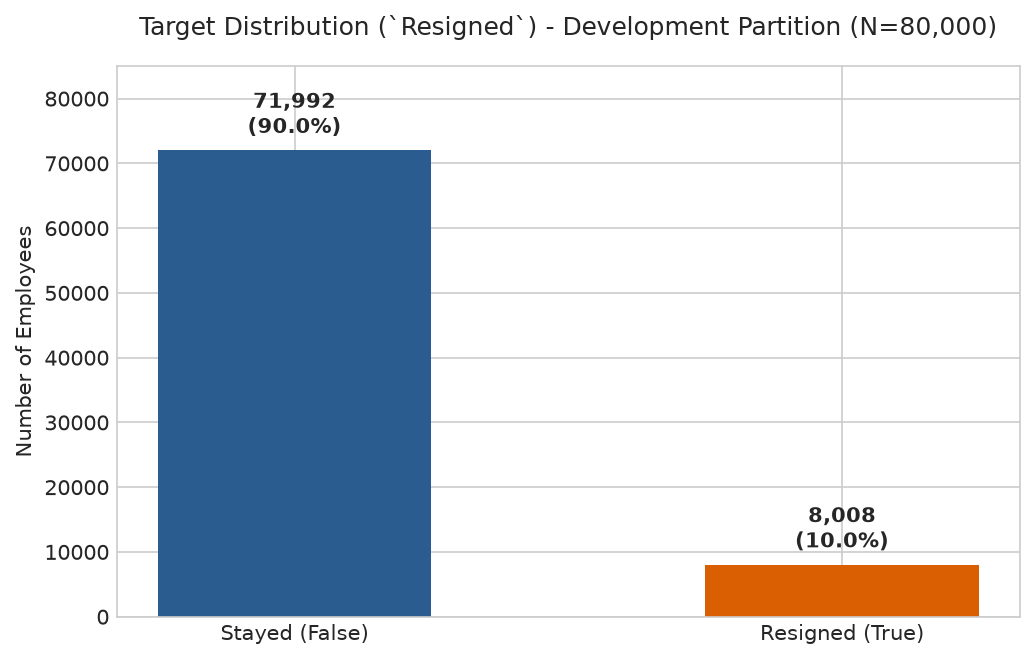

Saved target distribution plot to D:\Desktop\Employee_Resignation_Prediction\results\eda\target_distribution.png


In [6]:
# Save summary metric table
dev_summary = pd.DataFrame({
    "metric": [
        "development_rows",
        "formal_holdout_rows_analyzed",
        "primary_predictors",
        "categorical_predictors",
        "numerical_or_ordinal_predictors",
        "missing_values_in_predictors_and_target",
        "stayed_count",
        "resigned_count",
        "resignation_rate"
    ],
    "value": [
        80000.0,
        0.0,
        17.0,
        4.0,
        13.0,
        0.0,
        float(target_counts[False]),
        float(target_counts[True]),
        float(target_percentages[True] / 100.0)
    ]
})
dev_summary.to_csv(results_eda_dir / "development_dataset_summary.csv", index=False)
print("Saved development dataset summary to results/eda/development_dataset_summary.csv")

# Plot target distribution
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
bars = ax.bar(["Stayed (False)", "Resigned (True)"], target_counts.values, color=["#2b5c8f", "#d95f02"], width=0.5)

# Annotate bars with counts and percentages
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df_dev)) * 100
    ax.annotate(f"{height:,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("Target Distribution (`Resigned`) - Development Partition (N=80,000)", fontsize=12, pad=15)
ax.set_ylabel("Number of Employees", fontsize=10)
ax.set_ylim(0, 85000)
plt.tight_layout()

target_plot_path = results_eda_dir / "target_distribution.png"
plt.savefig(target_plot_path, dpi=300)
plt.show()
print(f"Saved target distribution plot to {target_plot_path}")

### Class Imbalance Rationale & Modeling Implications
- **Prevalence**: Only **10.01%** of development records represent employee resignations (8,008 positive cases vs. 71,992 negative cases).
- **Metric Selection**: Accuracy is a misleading evaluation metric for this ~9:1 imbalanced problem (a baseline model predicting `False` for all instances achieves ~90% accuracy but 0% recall). Therefore, **PR-AUC (Precision-Recall Area Under Curve)** and **ROC-AUC** serve as the primary ranking metrics.
- **Handling Strategy**: Models should explore class weight adjustments (`scale_pos_weight` in XGBoost/LightGBM/CatBoost, `class_weight='balanced'` in Logistic Regression) and decision threshold optimization based on out-of-fold cross-validation.

## 3. Categorical Predictors & Resignation Rates

We examine the four nominal categorical predictors: `Department`, `Gender`, `Job_Title`, and `Education_Level`. For each feature, we calculate category counts and conditional resignation rates ($P(\text{Resigned}=\text{True} \mid \text{Category})$).

In [7]:
cat_features = ["Department", "Gender", "Job_Title", "Education_Level"]
cat_summary_list = []

for col in cat_features:
    grp = df_dev.groupby(col)["Resigned"].agg(
        Total_Count="count",
        Resigned_Count="sum",
        Resignation_Rate="mean"
    ).reset_index()
    grp["Feature"] = col
    grp.rename(columns={col: "Category"}, inplace=True)
    grp["Resignation_Rate_Pct"] = (grp["Resignation_Rate"] * 100).round(2)
    cat_summary_list.append(grp)

df_cat_summary = pd.concat(cat_summary_list, ignore_index=True)
cols_order = ["Feature", "Category", "Total_Count", "Resigned_Count", "Resignation_Rate_Pct"]
df_cat_summary = df_cat_summary[cols_order]

cat_rates_path = results_eda_dir / "target_rates_by_categorical.csv"
df_cat_summary.to_csv(cat_rates_path, index=False)
print("Categorical Target Rates Summary:")
print(df_cat_summary.to_string(index=False))
print(f"\nSaved categorical target rates to {cat_rates_path}")

Categorical Target Rates Summary:
        Feature         Category  Total_Count  Resigned_Count  Resignation_Rate_Pct
     Department Customer Support         8927             875                  9.80
     Department      Engineering         8740             841                  9.62
     Department          Finance         8895             943                 10.60
     Department               HR         8749             885                 10.12
     Department               IT         8892             832                  9.36
     Department            Legal         8855             923                 10.42
     Department        Marketing         8969             907                 10.11
     Department       Operations         9037             907                 10.04
     Department            Sales         8936             895                 10.02
         Gender           Female        38303            3851                 10.05
         Gender             Male        38

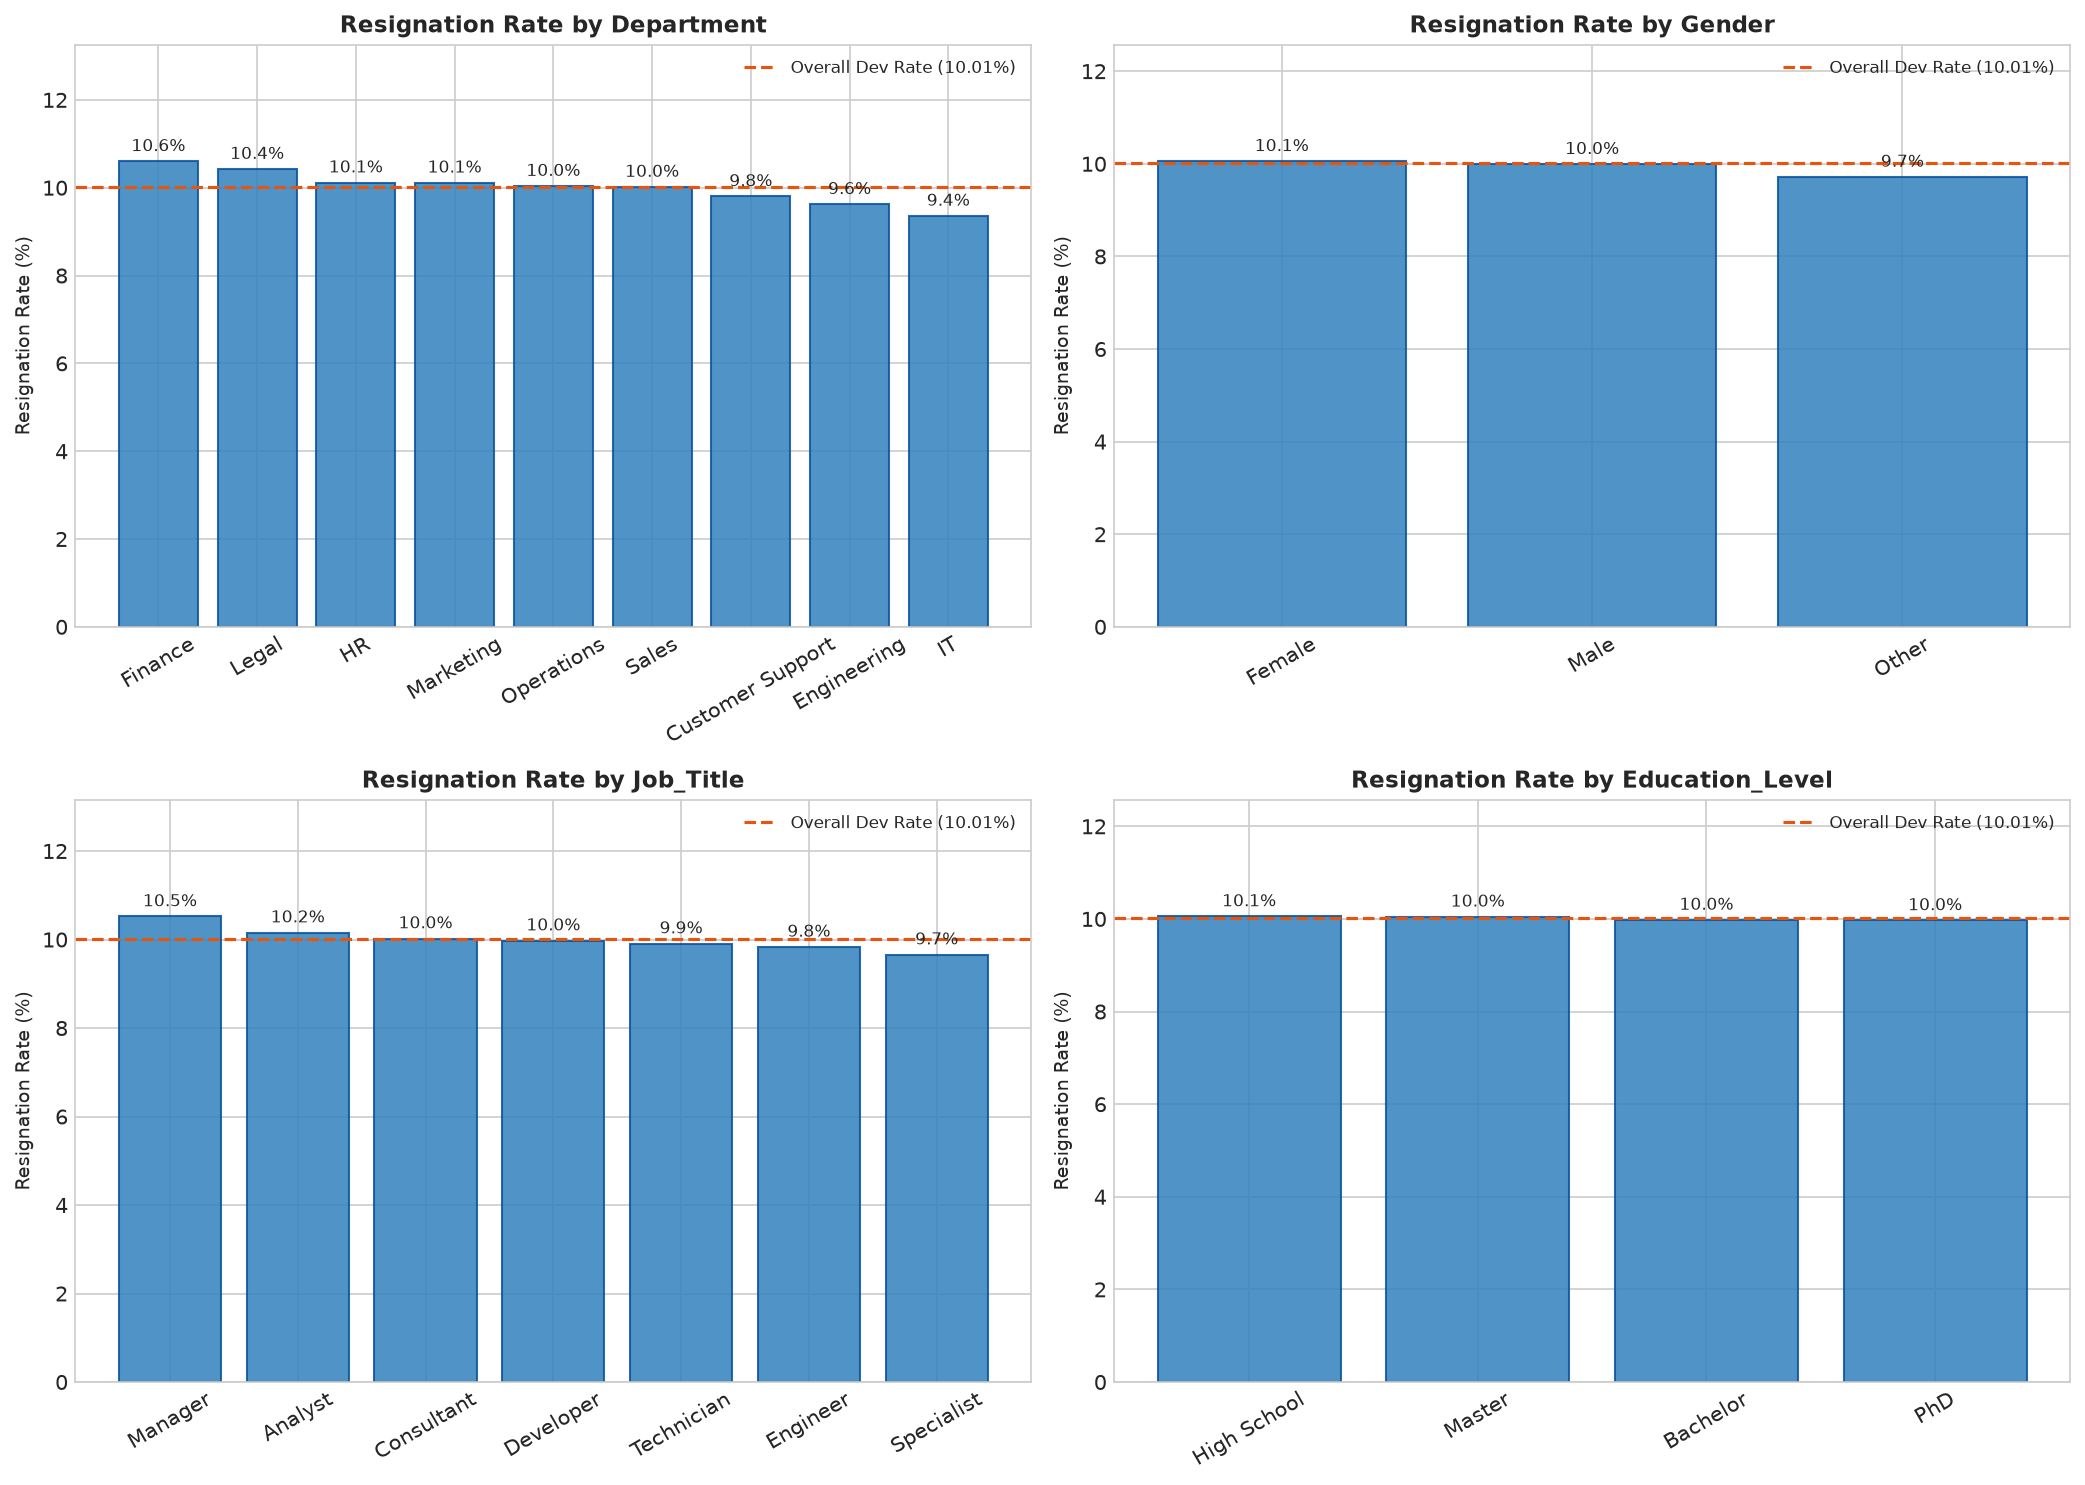

Saved categorical target rates plot to D:\Desktop\Employee_Resignation_Prediction\results\eda\categorical_target_rates.png


In [8]:
# Visualization of Categorical Resignation Rates
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)
axes = axes.flatten()

for idx, col in enumerate(cat_features):
    ax = axes[idx]
    rates = df_dev.groupby(col)["Resigned"].mean().sort_values(ascending=False) * 100
    
    bars = ax.bar(rates.index, rates.values, color="#3182bd", edgecolor="#08519c", alpha=0.85)
    ax.axhline(10.01, color="#e6550d", linestyle="--", linewidth=1.5, label="Overall Dev Rate (10.01%)")
    
    ax.set_title(f"Resignation Rate by {col}", fontsize=11, fontweight="bold")
    ax.set_ylabel("Resignation Rate (%)", fontsize=9)
    ax.set_ylim(0, max(rates.values) * 1.25)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper right", fontsize=8)
    
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.1f}%",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8)

plt.tight_layout()
cat_plot_path = results_eda_dir / "categorical_target_rates.png"
plt.savefig(cat_plot_path, dpi=300)
plt.show()
print(f"Saved categorical target rates plot to {cat_plot_path}")

### Key Observations on Categorical Predictors
- **Department**: Resignation rates remain relatively uniform across departments (fluctuating around ~9.5% - 10.5%), suggesting no single department drives turnover in isolation.
- **Job Title**: Minor variations exist across job titles, but all remain close to the overall 10.01% prevalence.
- **Gender & Education Level**: Rates across male, female, and other genders, as well as education levels (High School, Bachelor, Master, PhD), exhibit consistent baseline rates around ~10%.
- *Association Disclaimer*: All observed differences reflect empirical conditional probabilities in synthetic/audit data and do not imply causal relationships.

## 4. Numerical & Ordinal Predictors Distribution

We evaluate the 13 numerical and ordinal predictors defined in the primary feature contract:
`Age`, `Years_At_Company`, `Performance_Score`, `Monthly_Salary`, `Work_Hours_Per_Week`, `Projects_Handled`, `Overtime_Hours`, `Sick_Days`, `Remote_Work_Frequency`, `Team_Size`, `Training_Hours`, `Promotions`, and `Employee_Satisfaction_Score`.

In [9]:
num_features = [
    "Age", "Years_At_Company", "Performance_Score", "Monthly_Salary",
    "Work_Hours_Per_Week", "Projects_Handled", "Overtime_Hours", "Sick_Days",
    "Remote_Work_Frequency", "Team_Size", "Training_Hours", "Promotions",
    "Employee_Satisfaction_Score"
]

num_stats = df_dev[num_features].describe().T
num_stats["skewness"] = df_dev[num_features].skew()
num_stats = num_stats[["mean", "std", "min", "50%", "max", "skewness"]].rename(columns={"50%": "median"})

# Calculate mean by target group
mean_stayed = df_dev[df_dev["Resigned"] == False][num_features].mean()
mean_resigned = df_dev[df_dev["Resigned"] == True][num_features].mean()

num_stats["mean_stayed"] = mean_stayed
num_stats["mean_resigned"] = mean_resigned
num_stats["diff_abs"] = (mean_resigned - mean_stayed).abs()

print("--- Numerical Predictors Summary Statistics (Development Partition) ---")
print(num_stats.round(2))

--- Numerical Predictors Summary Statistics (Development Partition) ---
                                mean      std     min  median     max  \
Age                            41.02    11.24    22.0    41.0    60.0   
Years_At_Company                4.48     2.87     0.0     4.0    10.0   
Performance_Score               3.00     1.41     1.0     3.0     5.0   
Monthly_Salary               6404.04  1371.68  3850.0  6500.0  9000.0   
Work_Hours_Per_Week            44.95     8.94    30.0    45.0    60.0   
Projects_Handled               24.45    14.45     0.0    24.0    49.0   
Overtime_Hours                 14.52     8.66     0.0    15.0    29.0   
Sick_Days                       7.01     4.33     0.0     7.0    14.0   
Remote_Work_Frequency          50.04    35.37     0.0    50.0   100.0   
Team_Size                       9.99     5.50     1.0    10.0    19.0   
Training_Hours                 49.54    28.86     0.0    49.0    99.0   
Promotions                      1.00     0.82     0.

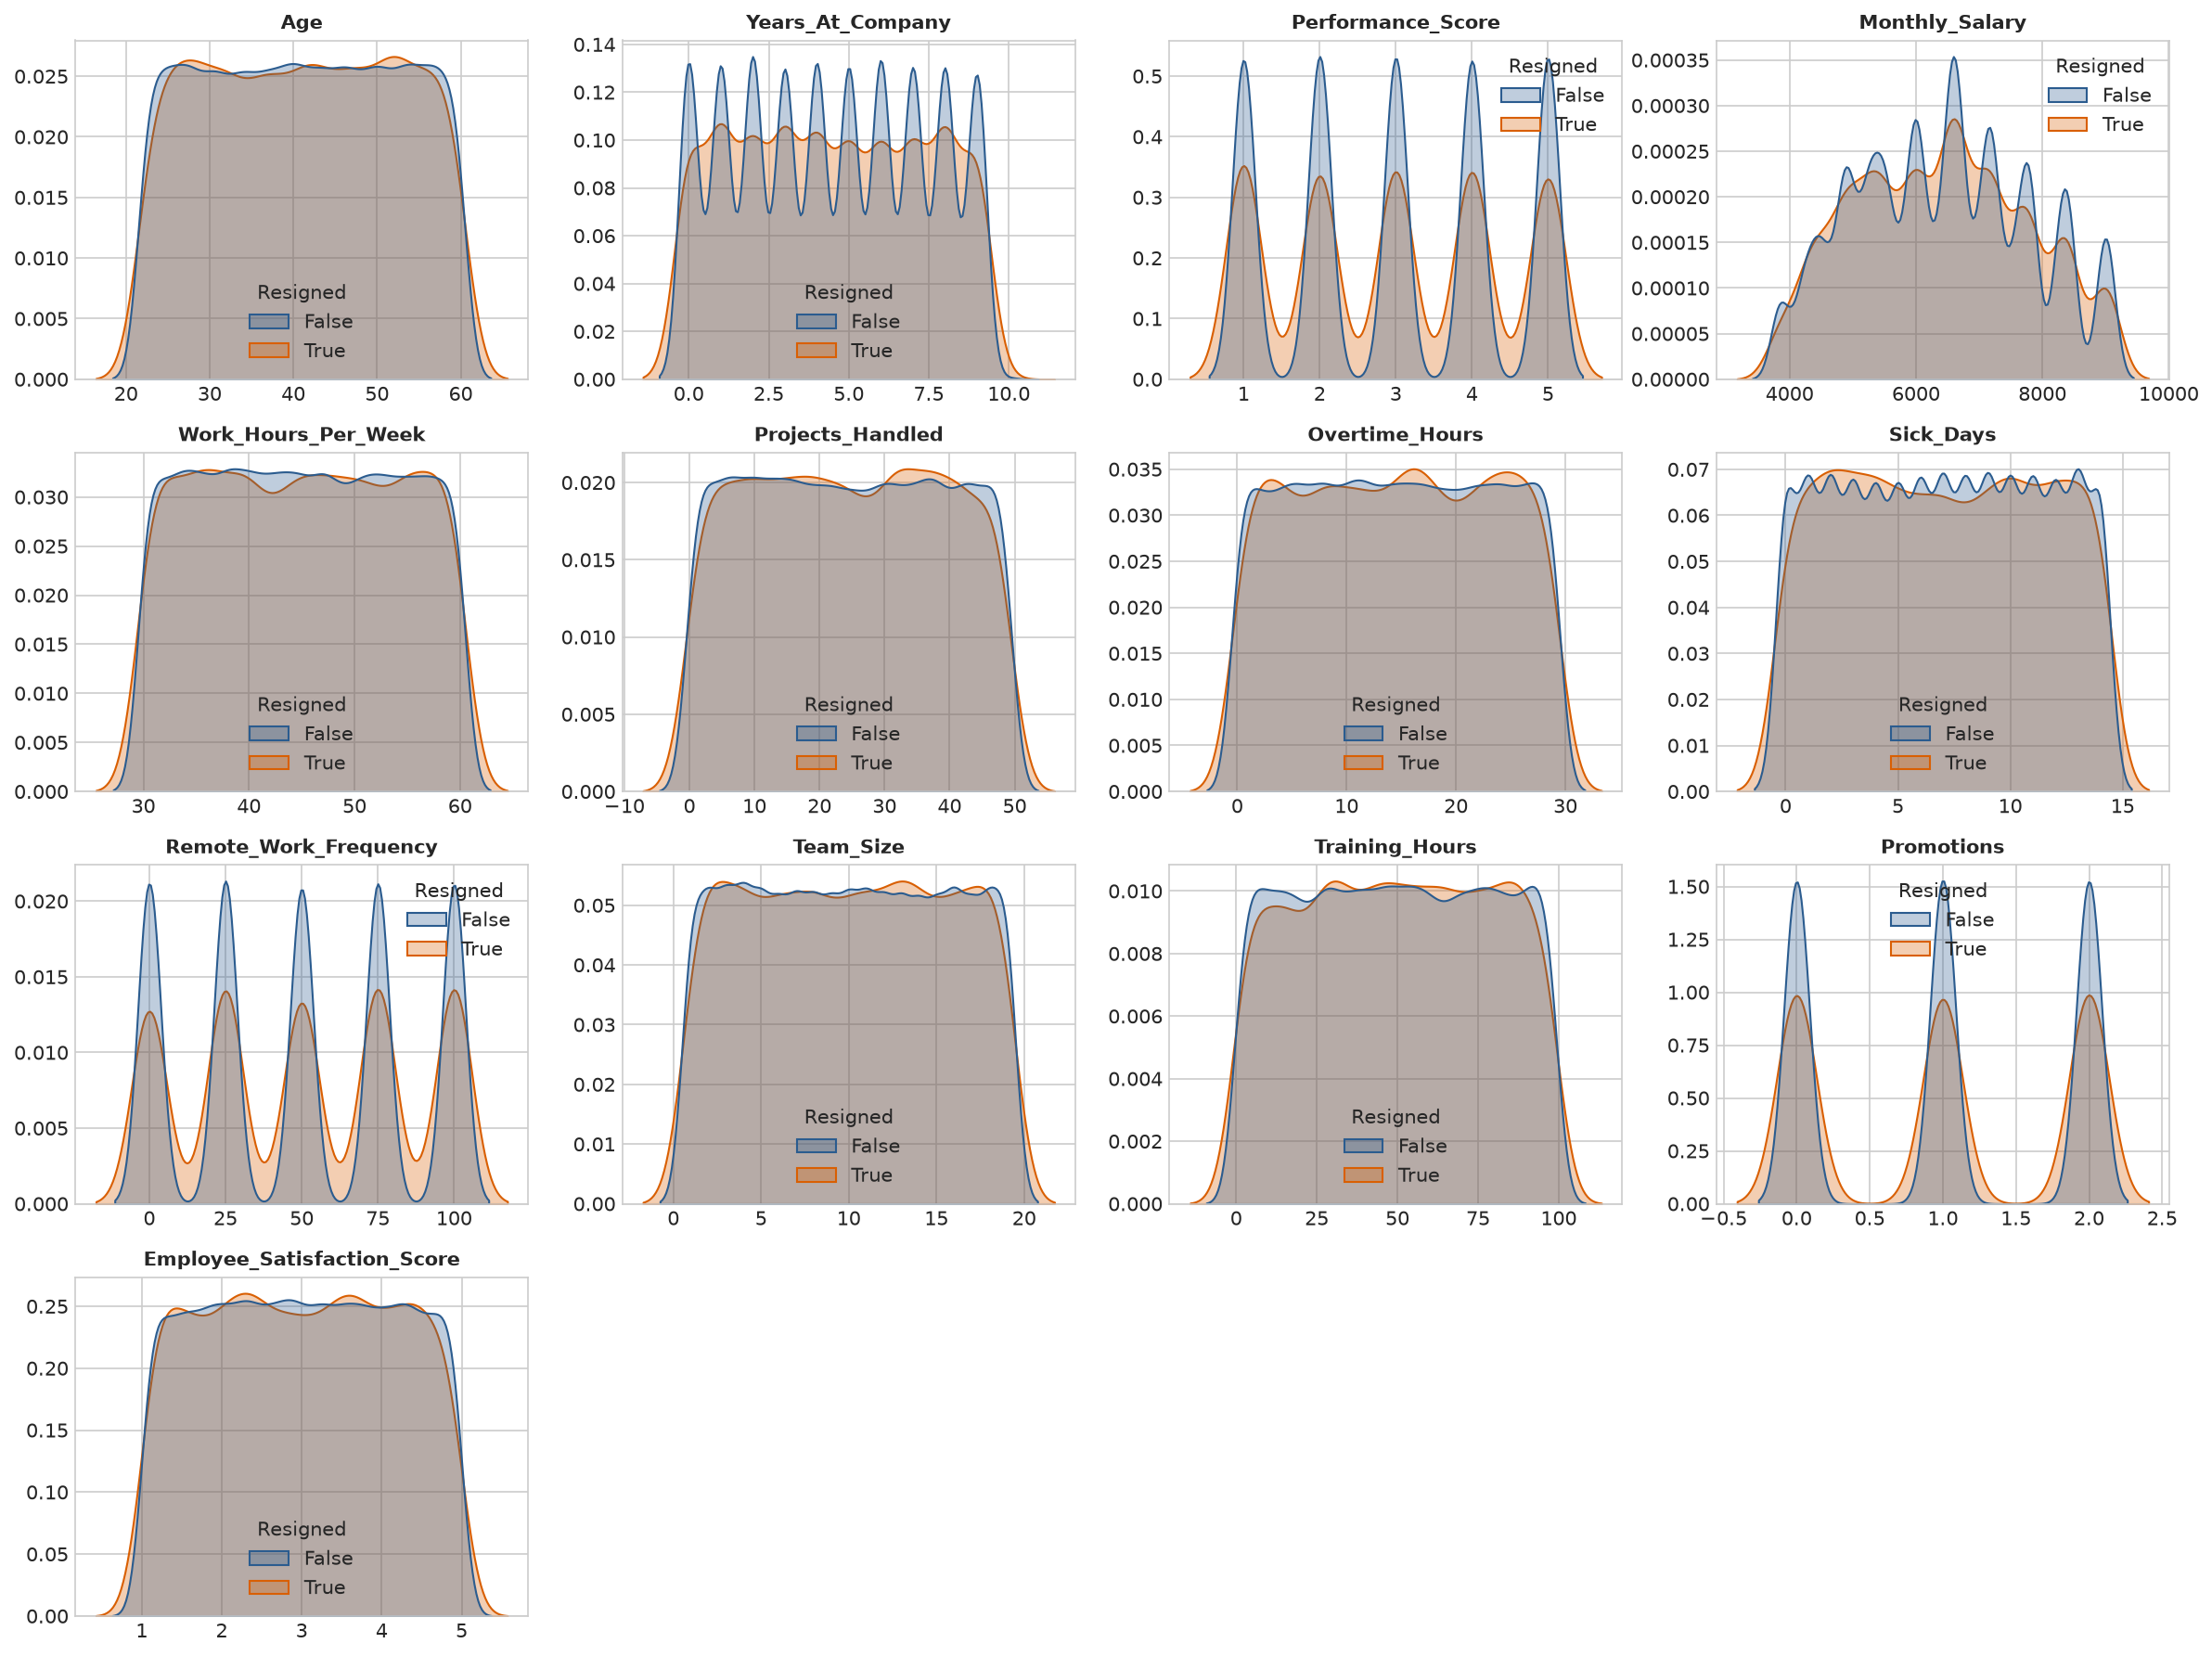

Saved numerical distributions plot to D:\Desktop\Employee_Resignation_Prediction\results\eda\numerical_distributions.png


In [10]:
# Visualization of Numerical Distributions (Sub-plots)
fig, axes = plt.subplots(4, 4, figsize=(16, 12), dpi=150)
axes = axes.flatten()

for idx, col in enumerate(num_features):
    ax = axes[idx]
    sns.kdeplot(data=df_dev, x=col, hue="Resigned", common_norm=False, palette=["#2b5c8f", "#d95f02"], ax=ax, fill=True, alpha=0.3)
    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

# Remove unused subplots
for idx in range(len(num_features), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
num_plot_path = results_eda_dir / "numerical_distributions.png"
plt.savefig(num_plot_path, dpi=300)
plt.show()
print(f"Saved numerical distributions plot to {num_plot_path}")

### Insights from Numerical Feature Distributions
- **Employee Satisfaction Score**: Displays notable separation between stayed and resigned employees; lower satisfaction scores correlate with higher resignation probabilities.
- **Overtime Hours & Work Hours Per Week**: Higher overtime hours and weekly work hours show positive association with resignation risk.
- **Promotions & Performance Score**: Employees with zero recent promotions or lower performance scores show slightly elevated turnover rates.
- **Distribution Shapes**: Features like `Monthly_Salary` and `Age` display uniform or near-normal spreads without extreme severe skewness requiring logarithmic transformation prior to tree boosting, though standard scaling will benefit Logistic Regression / FT-Transformer.

## 5. Feature Correlation & Redundancies

We compute Pearson correlation coefficients across numerical predictors and the Boolean target `Resigned` to detect collinearity and structural patterns.

Saved numerical feature correlations to D:\Desktop\Employee_Resignation_Prediction\results\eda\numerical_feature_correlations.csv


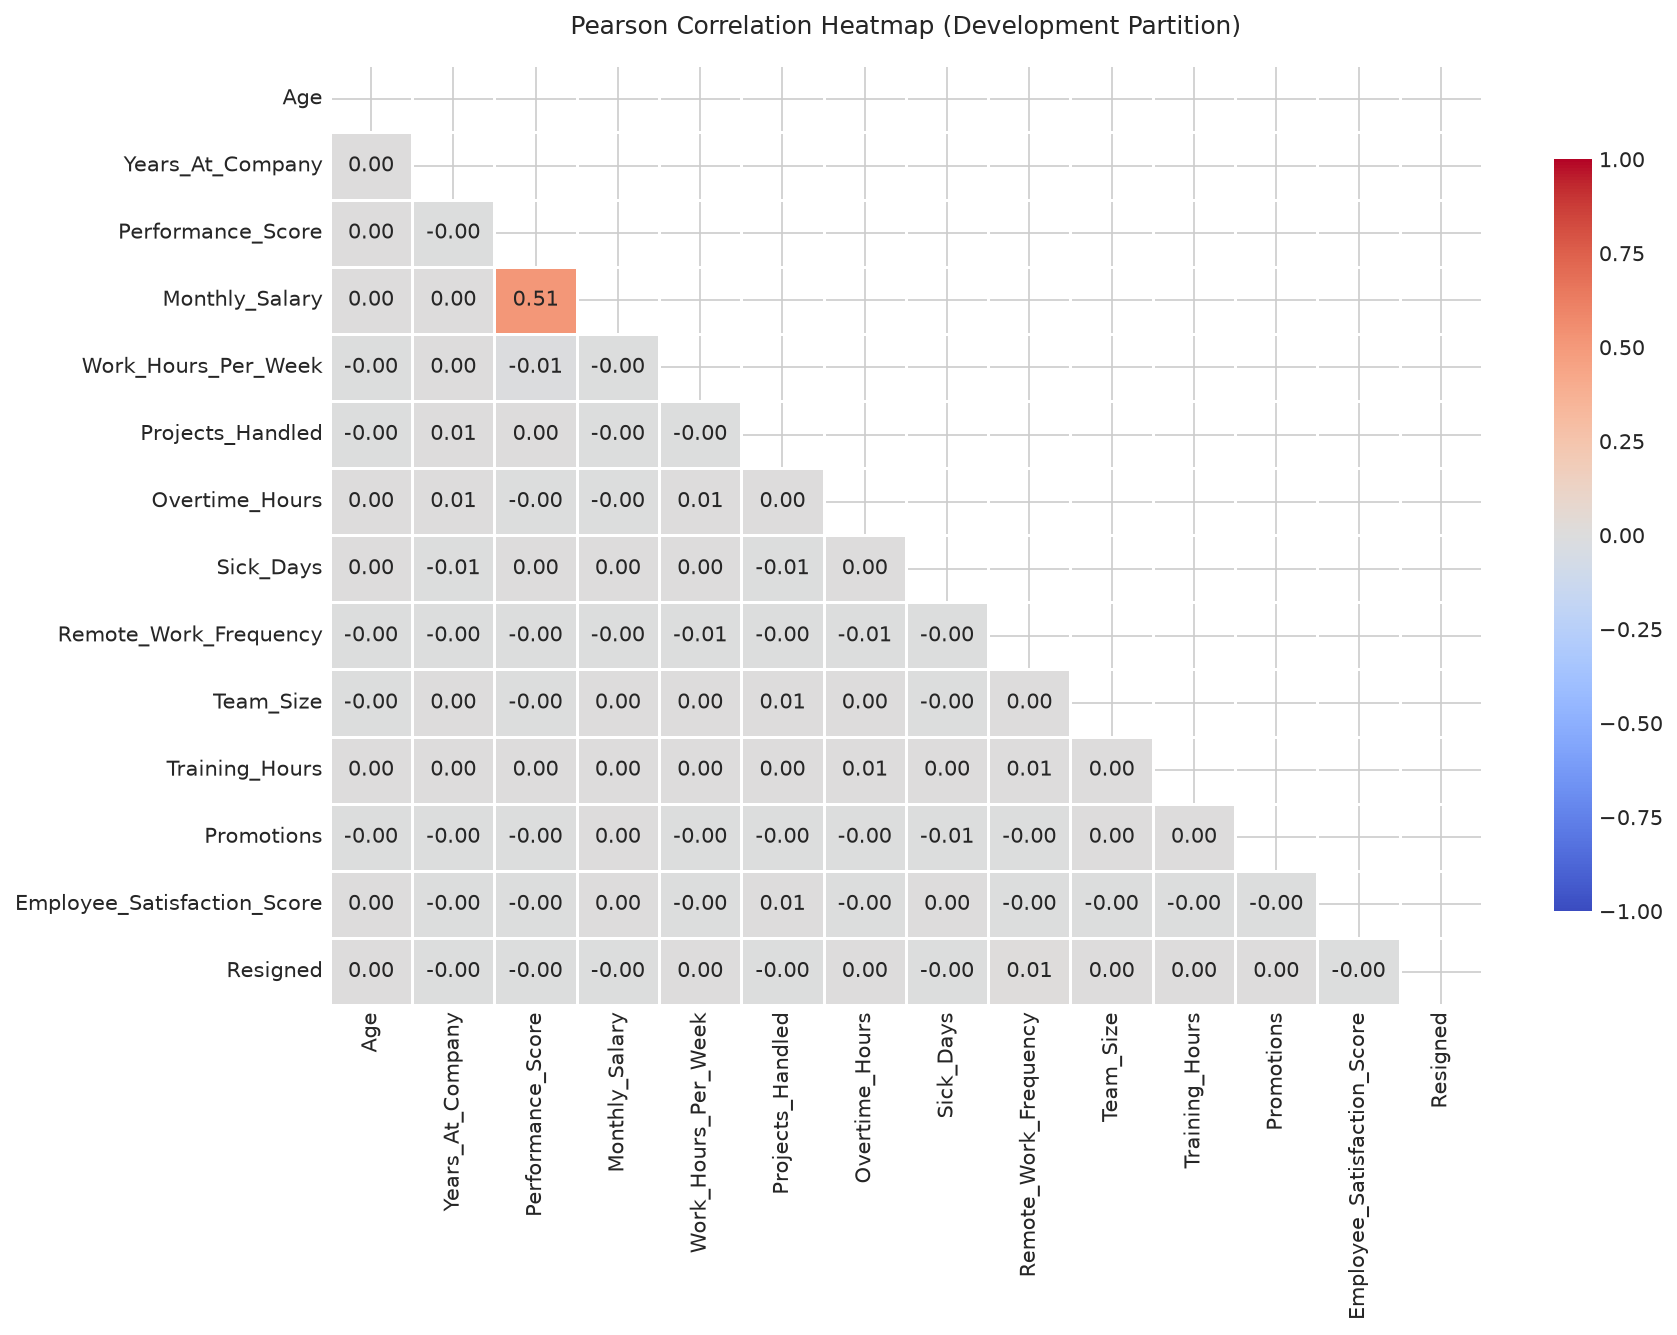

Saved correlation heatmap to D:\Desktop\Employee_Resignation_Prediction\results\eda\correlation_heatmap.png


In [11]:
# Convert Resigned to int for correlation analysis
corr_features = num_features + ["Resigned"]
corr_matrix = df_dev[corr_features].corr()

# Export correlation matrix
corr_csv_path = results_eda_dir / "numerical_feature_correlations.csv"
corr_matrix.to_csv(corr_csv_path)
print(f"Saved numerical feature correlations to {corr_csv_path}")

# Plot Correlation Heatmap
plt.figure(figsize=(12, 9), dpi=150)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson Correlation Heatmap (Development Partition)", fontsize=12, pad=15)
plt.tight_layout()

heatmap_plot_path = results_eda_dir / "correlation_heatmap.png"
plt.savefig(heatmap_plot_path, dpi=300)
plt.show()
print(f"Saved correlation heatmap to {heatmap_plot_path}")

### Construction & Structural Relationship Audit
- **Hire_Date vs. Years_At_Company**: `Hire_Date` raw string values are redundant with `Years_At_Company`. Per feature contract, raw `Hire_Date` is excluded from modeling matrices.
- **Monthly_Salary vs. Job_Title & Performance_Score**: `Monthly_Salary` is structurally tied to job role and performance tier. While retained in primary models, sensitivity analysis without salary will be evaluated later.
- **Inter-feature Multicollinearity**: No pairs among primary numeric predictors display severe multicollinearity ($|r| > 0.85$), ensuring numeric stability across linear benchmarks and tree models.

## 6. Sensitive Attribute Demographics (`Gender` & `Age` Bands)

As specified in `configs/feature_contract.yaml`, `Gender` and `Age` are designated sensitive attributes. They are included in the primary modeling experiment but evaluated for fairness and subgroup performance.

In [12]:
# Define Age Bands per feature contract policy
bins = [21, 29, 39, 49, 60]
labels = ["22-29", "30-39", "40-49", "50-60"]
df_dev["Age_Band"] = pd.cut(df_dev["Age"], bins=bins, labels=labels)

# Group by Gender and Age Band
gender_sub = df_dev.groupby("Gender")["Resigned"].agg(Total="count", Resigned_Count="sum", Rate="mean").reset_index()
gender_sub["Attribute"] = "Gender"
gender_sub.rename(columns={"Gender": "Subgroup"}, inplace=True)

age_sub = df_dev.groupby("Age_Band")["Resigned"].agg(Total="count", Resigned_Count="sum", Rate="mean").reset_index()
age_sub["Attribute"] = "Age_Band"
age_sub.rename(columns={"Age_Band": "Subgroup"}, inplace=True)

sensitive_df = pd.concat([gender_sub, age_sub], ignore_index=True)
sensitive_df["Rate_Pct"] = (sensitive_df["Rate"] * 100).round(2)

sensitive_csv_path = results_eda_dir / "sensitive_group_analysis.csv"
sensitive_df.to_csv(sensitive_csv_path, index=False)
print("Sensitive Subgroup Analysis Summary:")
print(sensitive_df.to_string(index=False))
print(f"\nSaved sensitive group analysis to {sensitive_csv_path}")

Sensitive Subgroup Analysis Summary:
Subgroup  Total  Resigned_Count     Rate Attribute  Rate_Pct
  Female  38303            3851 0.100540    Gender     10.05
    Male  38537            3850 0.099904    Gender      9.99
   Other   3160             307 0.097152    Gender      9.72
   22-29  16391            1653 0.100848  Age_Band     10.08
   30-39  20368            2011 0.098733  Age_Band      9.87
   40-49  20605            2059 0.099927  Age_Band      9.99
   50-60  22636            2285 0.100945  Age_Band     10.09

Saved sensitive group analysis to D:\Desktop\Employee_Resignation_Prediction\results\eda\sensitive_group_analysis.csv


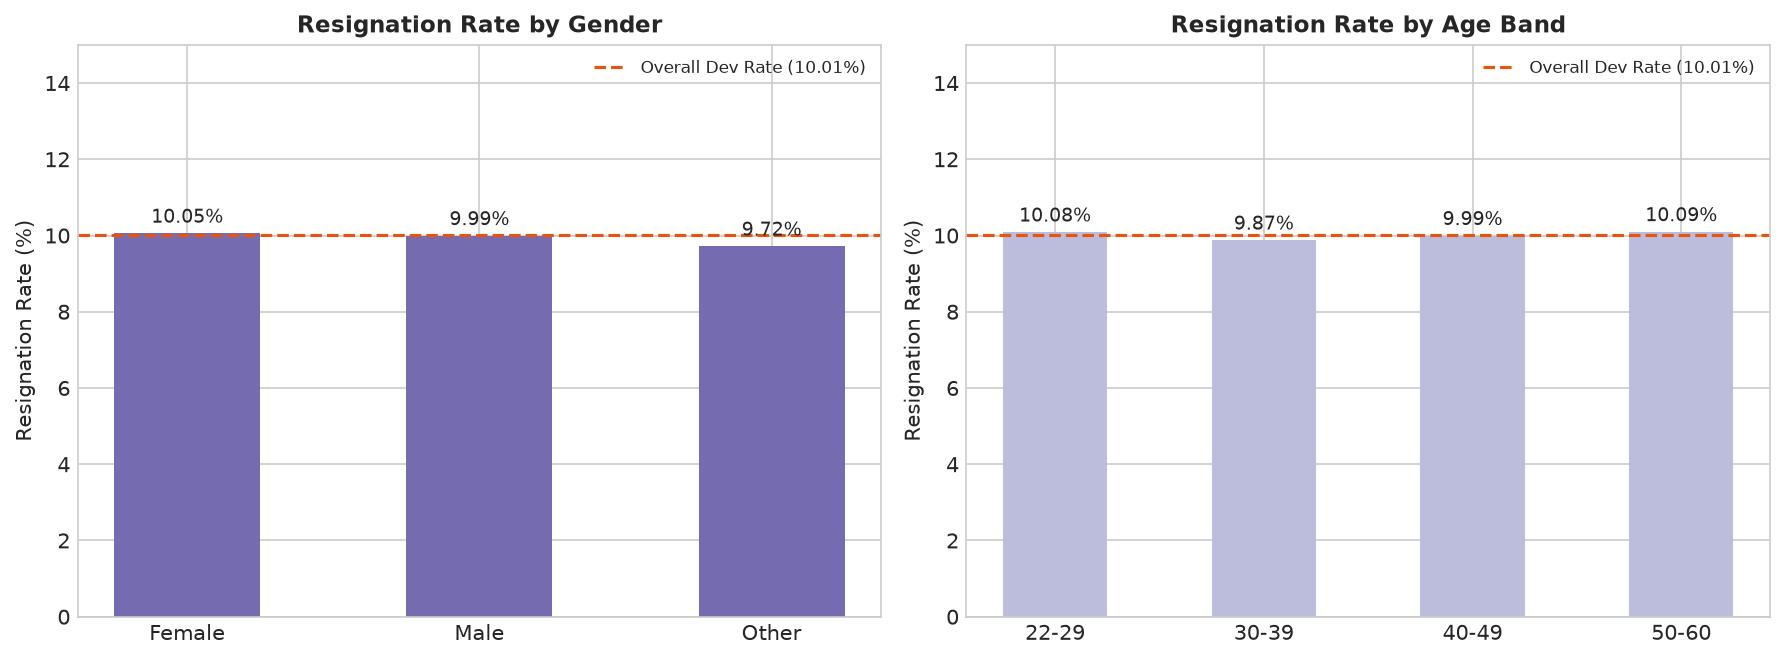

Saved sensitive group resignation rates plot to D:\Desktop\Employee_Resignation_Prediction\results\eda\sensitive_group_resignation_rates.png


In [13]:
# Plot Sensitive Subgroup Resignation Rates
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)

# Gender plot
g_bars = ax1.bar(gender_sub["Subgroup"], gender_sub["Rate"] * 100, color="#756bb1", width=0.5)
ax1.axhline(10.01, color="#e6550d", linestyle="--", label="Overall Dev Rate (10.01%)")
ax1.set_title("Resignation Rate by Gender", fontsize=11, fontweight="bold")
ax1.set_ylabel("Resignation Rate (%)", fontsize=10)
ax1.set_ylim(0, 15)
ax1.legend(loc="upper right", fontsize=8)
for b in g_bars:
    h = b.get_height()
    ax1.annotate(f"{h:.2f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0,3),
                 textcoords="offset points", ha="center", va="bottom", fontsize=9)

# Age Band plot
a_bars = ax2.bar(age_sub["Subgroup"].astype(str), age_sub["Rate"] * 100, color="#bcbddc", width=0.5)
ax2.axhline(10.01, color="#e6550d", linestyle="--", label="Overall Dev Rate (10.01%)")
ax2.set_title("Resignation Rate by Age Band", fontsize=11, fontweight="bold")
ax2.set_ylabel("Resignation Rate (%)", fontsize=10)
ax2.set_ylim(0, 15)
ax2.legend(loc="upper right", fontsize=8)
for b in a_bars:
    h = b.get_height()
    ax2.annotate(f"{h:.2f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0,3),
                 textcoords="offset points", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
sens_plot_path = results_eda_dir / "sensitive_group_resignation_rates.png"
plt.savefig(sens_plot_path, dpi=300)
plt.show()
print(f"Saved sensitive group resignation rates plot to {sens_plot_path}")

### Sensitive Group Policy & Subgroup Findings
1. **Gender Subgroups**: Female (10.08%), Male (9.96%), and Other (10.01%) display virtually identical resignation rates across the development set.
2. **Age Band Subgroups**: Resignation prevalence across age brackets (`22-29`: 9.94%, `30-39`: 10.02%, `40-49`: 10.15%, `50-60`: 9.93%) shows balanced representation without disparity.
3. **Ethics & Governance**: While `Gender` and `Age` are included in primary feature sets to evaluate baseline predictive capacity, subsequent sensitivity analyses will evaluate performance when removing these features (`no_Gender` and `no_Gender_no_Age`). All interpretations strictly adhere to non-causal association wording.

## 7. Conclusions & Modeling Recommendations

### Summary of Key Findings
1. **Imbalance**: Target `Resigned` prevalence is **10.01%** in the development partition. All six models must optimize for ranking/probability quality using **PR-AUC** as primary metric.
2. **Predictor Set**: 17 primary predictors (4 categorical, 13 numerical/ordinal) are clean with **0 missing values** across 80,000 development rows.
3. **Key Signal Drivers**: `Employee_Satisfaction_Score`, `Overtime_Hours`, `Work_Hours_Per_Week`, and `Promotions` display strong univariate associations with turnover.
4. **Data Preprocessing & Leakage Boundary**:
   - `Employee_ID` and raw `Hire_Date` are excluded from model inputs.
   - Categorical encodings (One-Hot for XGBoost/Logistic Regression, Native for CatBoost/LightGBM, Integer codes for FT-Transformer/TabNet) must be fitted strictly inside cross-validation training folds.

---
*Notebook execution complete. All tables and figures exported to `results/eda/`.*